Saving PJME_hourly.csv.zip to PJME_hourly.csv (1).zip
              Datetime  PJME_MW
0  2002-12-31 01:00:00  26498.0
1  2002-12-31 02:00:00  25147.0
2  2002-12-31 03:00:00  24574.0
3  2002-12-31 04:00:00  24393.0
4  2002-12-31 05:00:00  24860.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  object 
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.2+ MB
None
             PJME_MW
count  145366.000000
mean    32080.222831
std      6464.012166
min     14544.000000
25%     27573.000000
50%     31421.000000
75%     35650.000000
max     62009.000000

STATISTICAL ANALYSIS
Mean: 32078.930711455927
Median: 31420.0
Mode: 30051.0
Minimum: 14544.0
Maximum: 62009.0
Standard Deviation: 6464.257071265533
Variance: 41786619.48340645
Square Root of Variance: 6464.257071265533

OUTLIER DETECTION

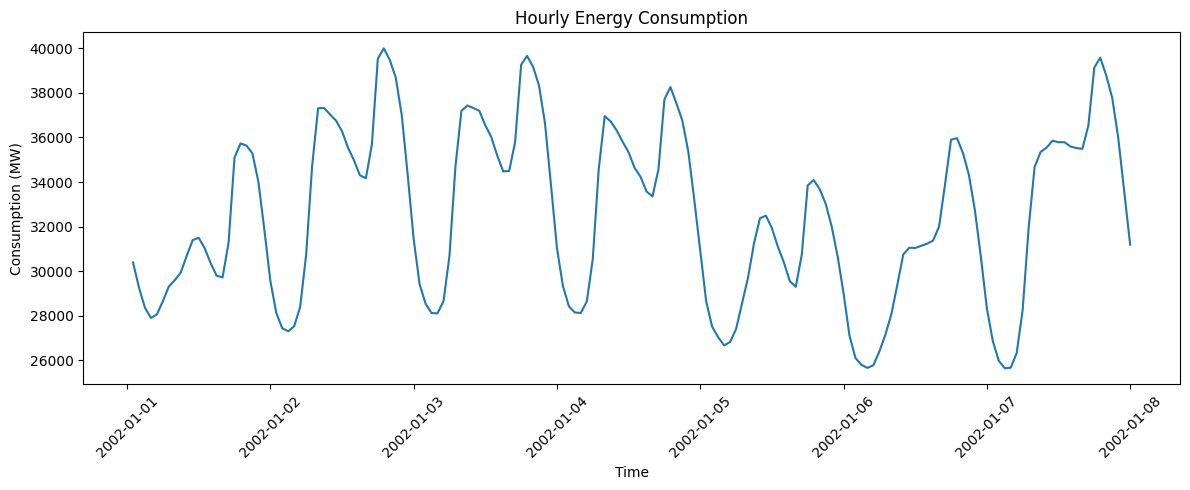


VISUALIZATION 2: ROLLING AVERAGE


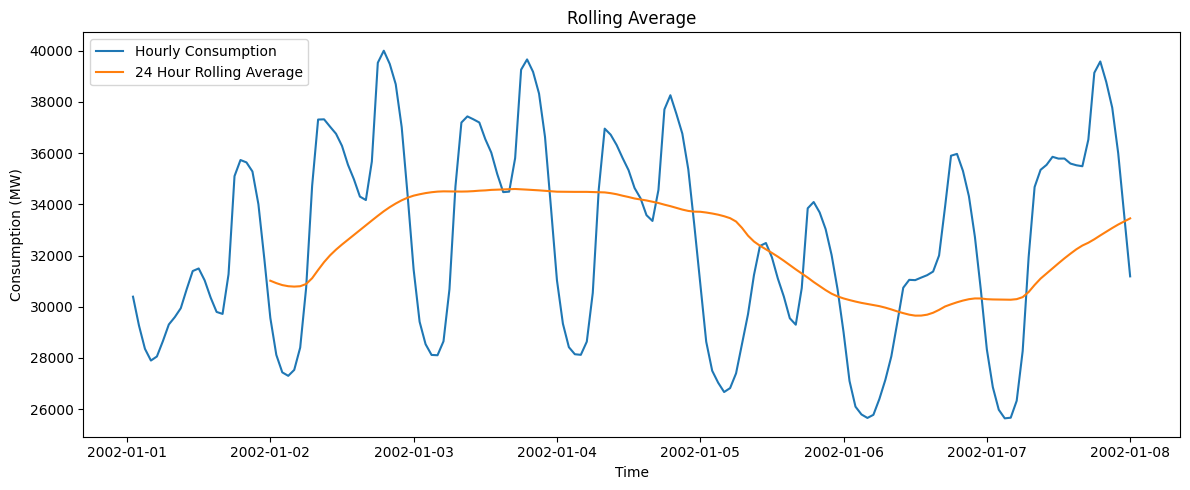


VISUALIZATION 3: MONTHLY COMPARISON


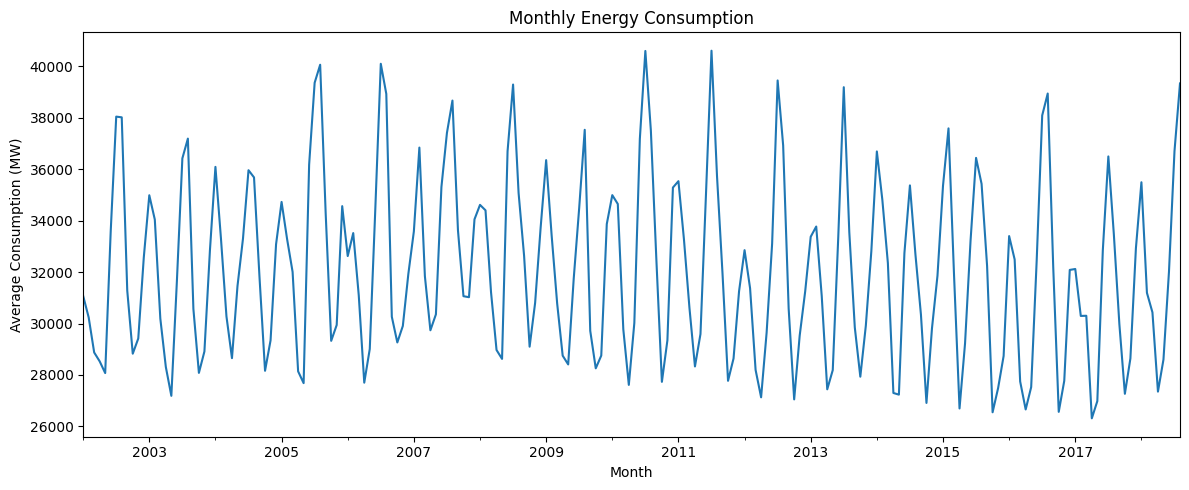


VISUALIZATION 4: DISTRIBUTION


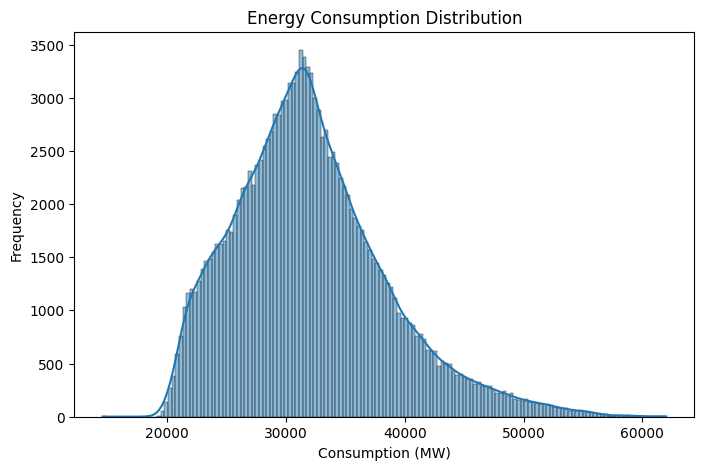


VISUALIZATION 5: BOXPLOT


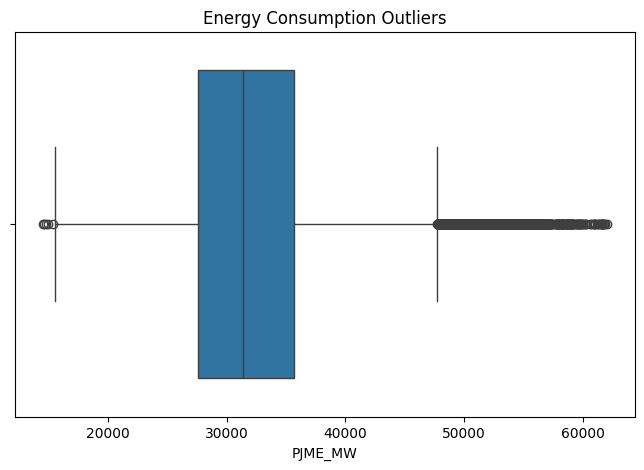


VISUALIZATION 6: HEATMAP


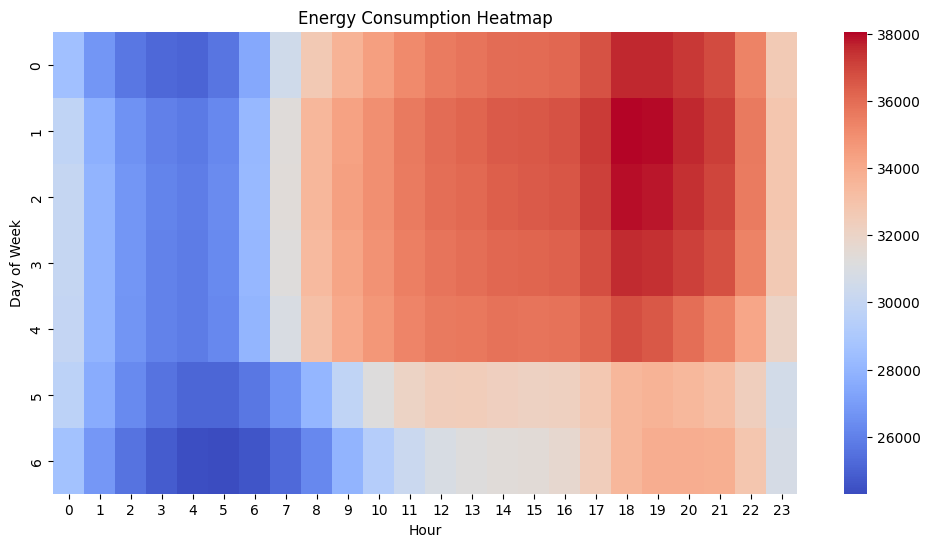


ALL ANALYSIS COMPLETED SUCCESSFULLY


In [ ]:
#NAME- ASMITA K. CHAVAN
#ROLL NO:- 08
#CLASS - TY CORE-4
#BATCH - A


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import zipfile
import os

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

if filename.endswith('.zip'):
    with zipfile.ZipFile(filename, 'r') as z:
        csv_files = [f for f in z.namelist() if f.endswith('.csv')]
        csv_file = next((f for f in csv_files if 'PJME_hourly.csv' in f), csv_files[0])
        df = pd.read_csv(z.open(csv_file))
else:
    df = pd.read_csv(filename)

print(df.head())
print(df.info())
print(df.describe())

df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime')
df = df.set_index('Datetime')
df = df[~df.index.duplicated(keep='first')]
df = df.asfreq('h')

df['PJME_MW'] = df['PJME_MW'].interpolate(
    method='time',
    limit_direction='both'
)

data = df['PJME_MW'].dropna()

print("\nSTATISTICAL ANALYSIS")

print("Mean:", np.mean(data))
print("Median:", np.median(data))
print("Mode:", stats.mode(data, keepdims=True).mode[0])
print("Minimum:", np.min(data))
print("Maximum:", np.max(data))
print("Standard Deviation:", np.std(data))
print("Variance:", np.var(data))
print("Square Root of Variance:", math.sqrt(np.var(data)))

print("\nOUTLIER DETECTION")

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[(data < lower) | (data > upper)]

print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Total Outliers:", len(outliers))

df['Hour'] = df.index.hour
df['Day'] = df.index.day
df['Month'] = df.index.month
df['DayOfWeek'] = df.index.dayofweek
df['Time'] = np.arange(len(df))

print("\nCORRELATION ANALYSIS")

correlation = df[
    ['PJME_MW', 'Hour', 'Day', 'Month', 'DayOfWeek']
].corr()

print(correlation)

print("\nTREND ANALYSIS")

daily = df['PJME_MW'].resample('D').mean()

print(daily.head())
print("Average Daily Change:", daily.diff().mean())

print("\nHYPOTHESIS TESTING")

mid = len(data) // 2

first_half = data.iloc[:mid]
second_half = data.iloc[mid:]

t_stat, p_value = stats.ttest_ind(
    first_half,
    second_half,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Significant difference exists.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant difference exists.")

print("\nLINEAR REGRESSION")

X = df[['Time', 'Hour', 'Day', 'Month', 'DayOfWeek']]
y = df['PJME_MW']

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Predictions:", predictions[:10])

print("\nMODEL EVALUATION")

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)
mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("MAPE:", mape)

print("\nDAILY AND MONTHLY SUMMARY")

hourly = df['PJME_MW']

daily_summary = hourly.resample('D').agg(['mean', 'max', 'min'])
monthly_summary = hourly.resample('MS').agg(['mean', 'max', 'min'])

print("Daily Summary:")
print(daily_summary.head())

print("Monthly Summary:")
print(monthly_summary.head())

print("\nPEAK AND AVERAGE DEMAND")

print("Peak Demand:", hourly.max())
print("Average Demand:", hourly.mean())
print("Peak Demand Time:", hourly.idxmax())

print("\nVISUALIZATION 1: HOURLY TIME SERIES")

plt.figure(figsize=(12, 5))
plt.plot(hourly.iloc[:168])
plt.title("Hourly Energy Consumption")
plt.xlabel("Time")
plt.ylabel("Consumption (MW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nVISUALIZATION 2: ROLLING AVERAGE")

rolling = hourly.rolling(window=24).mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly.iloc[:168], label="Hourly Consumption")
plt.plot(rolling.iloc[:168], label="24 Hour Rolling Average")
plt.title("Rolling Average")
plt.xlabel("Time")
plt.ylabel("Consumption (MW)")
plt.legend()
plt.tight_layout()
plt.show()

print("\nVISUALIZATION 3: MONTHLY COMPARISON")

plt.figure(figsize=(12, 5))
monthly_summary['mean'].plot()
plt.title("Monthly Energy Consumption")
plt.xlabel("Month")
plt.ylabel("Average Consumption (MW)")
plt.tight_layout()
plt.show()

print("\nVISUALIZATION 4: DISTRIBUTION")

plt.figure(figsize=(8, 5))
sns.histplot(hourly, kde=True)
plt.title("Energy Consumption Distribution")
plt.xlabel("Consumption (MW)")
plt.ylabel("Frequency")
plt.show()

print("\nVISUALIZATION 5: BOXPLOT")

plt.figure(figsize=(8, 5))
sns.boxplot(x=hourly)
plt.title("Energy Consumption Outliers")
plt.show()

print("\nVISUALIZATION 6: HEATMAP")

heatmap_data = df.pivot_table(
    values='PJME_MW',
    index='DayOfWeek',
    columns='Hour',
    aggfunc='mean'
)

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='coolwarm')
plt.title("Energy Consumption Heatmap")
plt.xlabel("Hour")
plt.ylabel("Day of Week")
plt.show()

print("\nALL ANALYSIS COMPLETED SUCCESSFULLY")